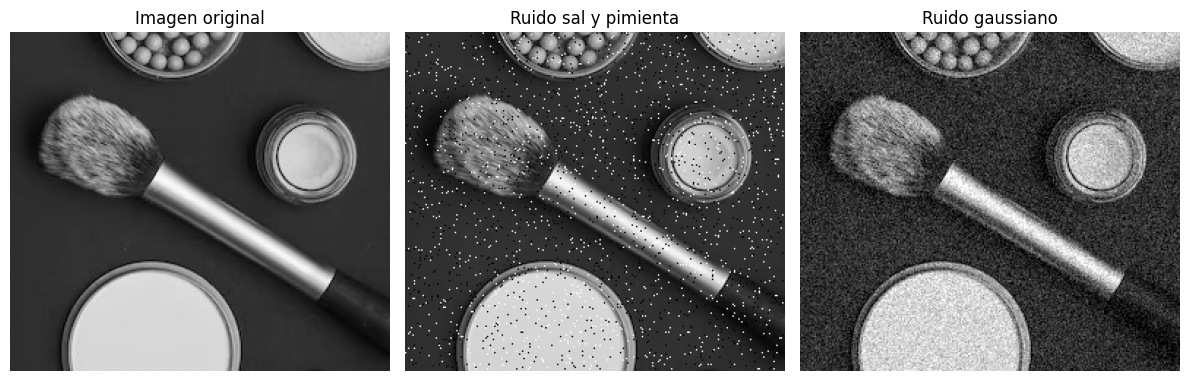

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from torch import lt

# Cargar imagen en escala de grises (usa una de las imagen de tu mini reto
#que tomaste, luego la cambias por alguna de las imágenes binarias que
#creaste)

imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)
# -------------------------------
# Función para agregar ruido sal y pimienta

def agregar_ruido_sal_pimienta(imagen, cantidad=0.05):
    salida = np.copy(imagen)
    num_pixels = int(cantidad * imagen.size)
    # añadir ruido sal
    coords=[np.random.randint(0, i - 1, num_pixels) for i in imagen.shape]
    salida[coords[0], coords[1]] = 255

    # añadir ruido pimienta
    coords=[np.random.randint(0, i - 1, num_pixels) for i in imagen.shape]
    salida[coords[0], coords[1]] = 0

    return salida

# -------------------------------
# Función para agregar ruido gaussiano
def agregar_ruido_gaussiano(imagen, media=0, sigma=20):
    gauss = np.random.normal(media, sigma, imagen.shape).astype(np.int16)
    imagen_ruido = imagen.astype(np.int16) + gauss
    imagen_ruido = np.clip(imagen_ruido, 0, 255).astype(np.uint8)
    return imagen_ruido
# -------------------------------
# Aplicar ruido
imagen_sal_pimienta = agregar_ruido_sal_pimienta(imagen, cantidad=0.02)
imagen_gaussiana = agregar_ruido_gaussiano(imagen, media=0, sigma=20)
# -------------------------------
# Mostrar resultados
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(imagen, cmap='gray')
axs[0].set_title('Imagen original')
axs[0].axis('off')
axs[1].imshow(imagen_sal_pimienta, cmap='gray')
axs[1].set_title('Ruido sal y pimienta')
axs[1].axis('off')
axs[2].imshow(imagen_gaussiana, cmap='gray')
axs[2].set_title('Ruido gaussiano')
axs[2].axis('off')
plt.tight_layout()
plt.show()

## Filtro paso bajas

In [2]:
#Filtro Promediador
imagen_promediador = cv2.blur(imagen_sal_pimienta, (5, 5))


#Filtro Promediadorp pesado
N=8
kernel= np.array([[1, 1, 1],[1,N,1],[1, 1, 1]], np.float32)/(N+8)
imagen_promedio_pesado = cv2.filter2D(imagen_sal_pimienta, -1, kernel)


#Filtro gausiano
imagen_gaussiana = cv2.GaussianBlur(imagen_sal_pimienta, (5, 5), 1)

#Filtro de Mediana
imagen_mediana = cv2.medianBlur(imagen_sal_pimienta, 5)

#Filtro de Moda
from scipy import stats

def filtro_moda(imagen, tamano_vecindad=3):
    # Obtener las dimensiones de la imagen
    filas, columnas = imagen.shape
    # Crear una imagen de salida con ceros
    salida = np.zeros((filas, columnas), dtype=np.uint8)
    # Calcular el desplazamiento para la vecindad
    desplazamiento = tamano_vecindad // 2

    # Recorrer cada píxel de la imagen
    for i in range(filas):
        for j in range(columnas):
            # Definir los límites de la vecindad
            fila_inicio = max(0, i - desplazamiento)
            fila_fin = min(filas, i + desplazamiento + 1)
            columna_inicio = max(0, j - desplazamiento)
            columna_fin = min(columnas, j + desplazamiento + 1)

            # Extraer la vecindad del píxel actual
            vecindad = imagen[fila_inicio:fila_fin, columna_inicio:columna_fin]
            # Calcular la moda de la vecindad
            moda = stats.mode(vecindad, axis=None)[0][0]
            # Asignar el valor de la moda al píxel de salida
            salida[i, j] = moda

    return salida

imagen_moda = filtro_moda(imagen_sal_pimienta, tamano_vecindad=3)

#Filtro Bilateral

BF = cv2.bilateralFilter(IMG, 9, 75, 75)


IndexError: invalid index to scalar variable.

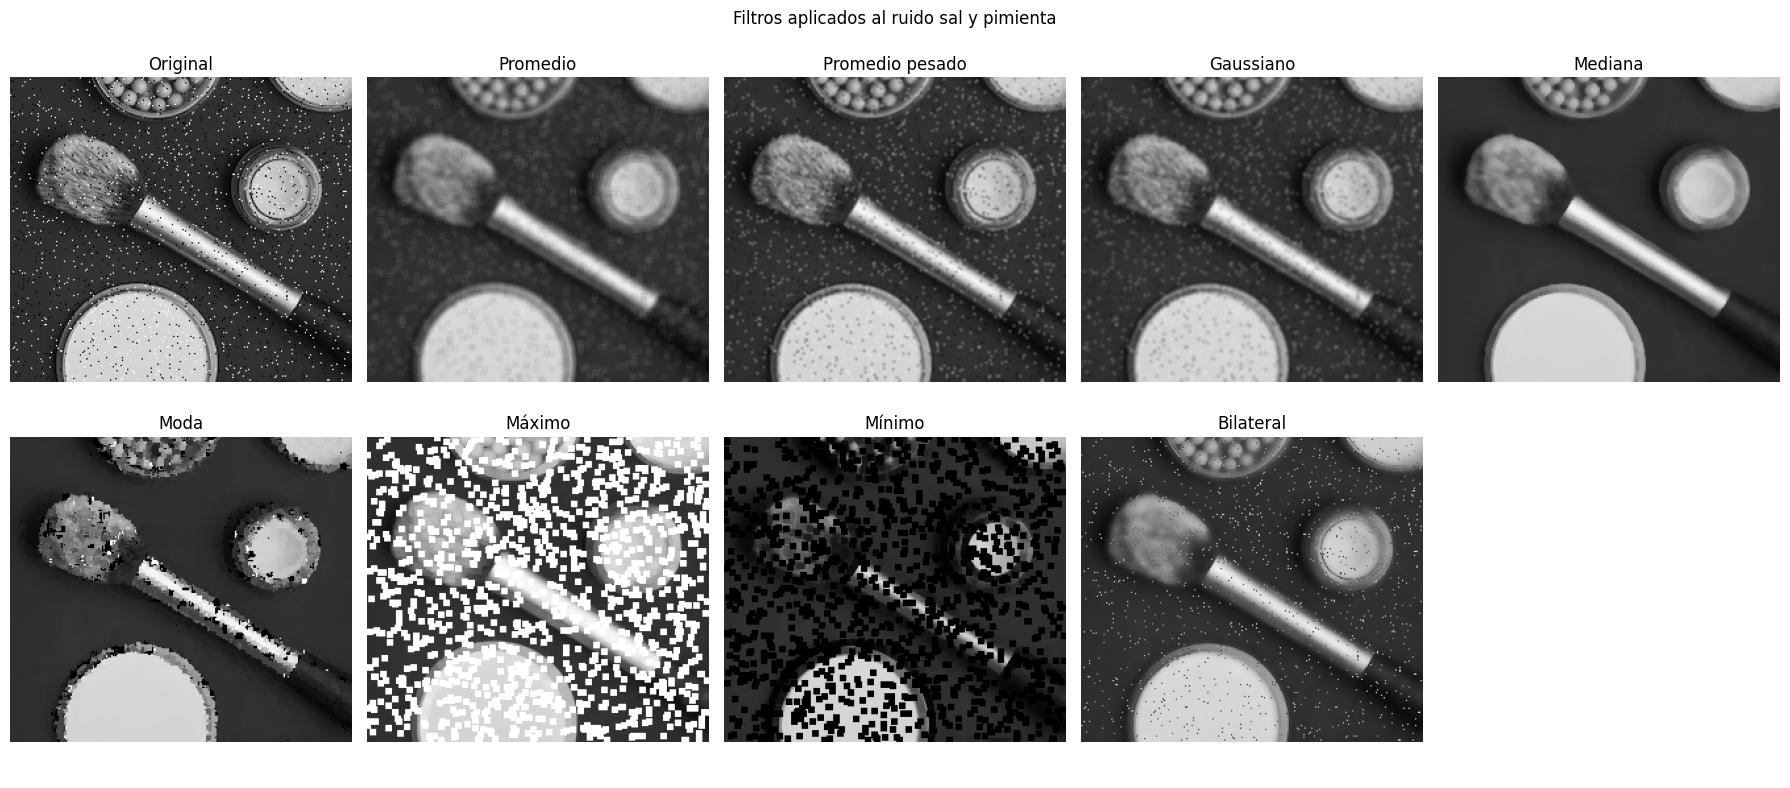

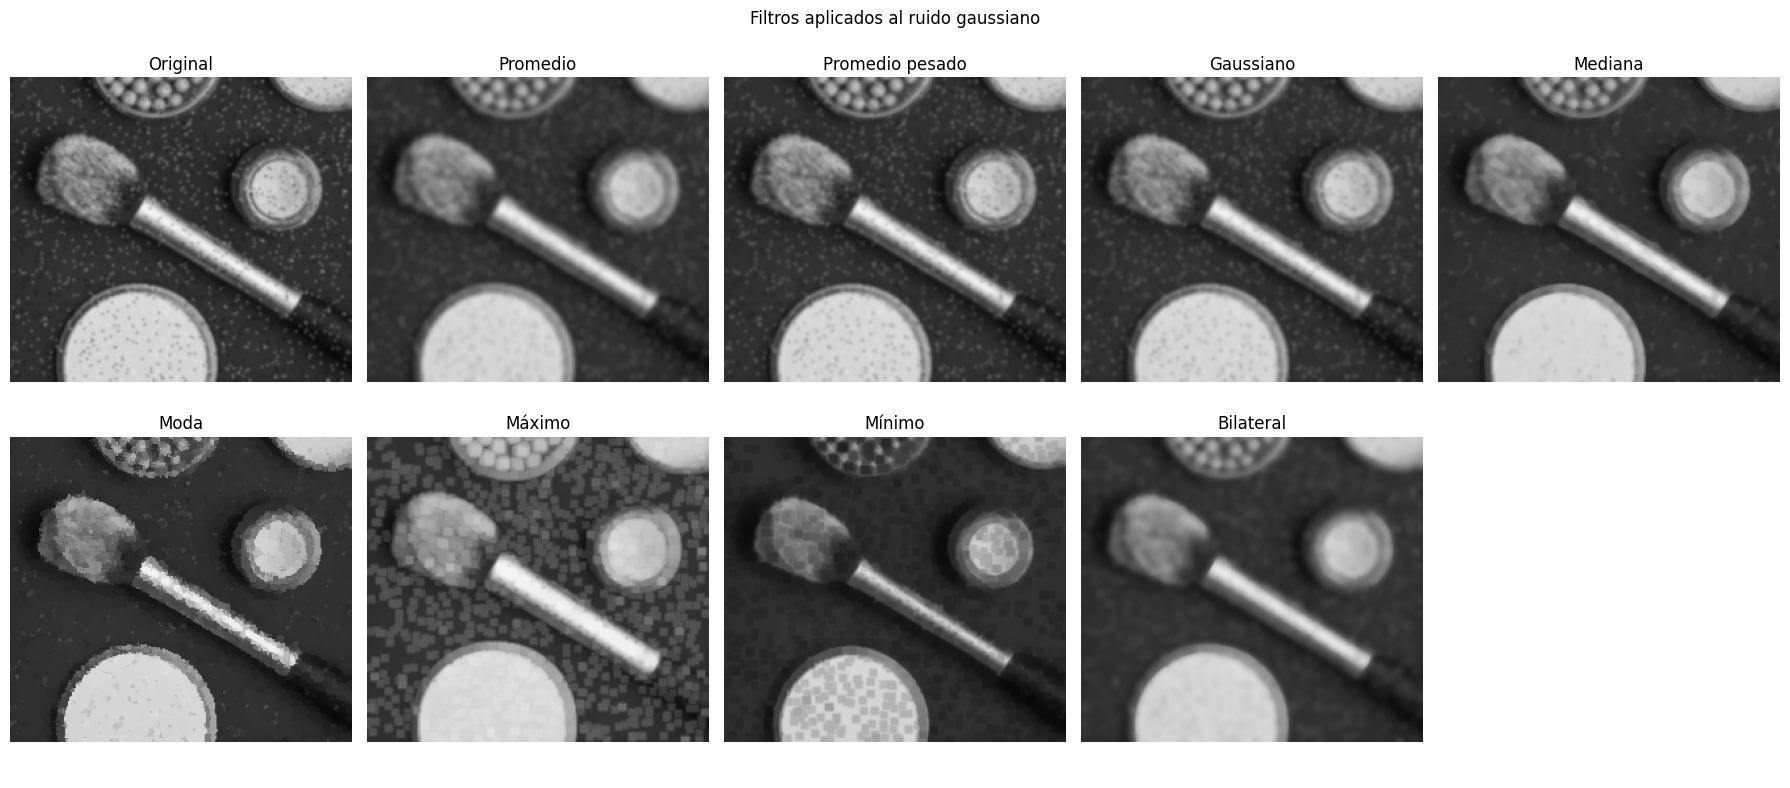

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

def filtro_moda(imagen, tamano=5):
    def moda(vecindario):
        frecuencias = np.bincount(vecindario.astype(np.uint8), minlength=256)
        return np.argmax(frecuencias)

    return ndimage.generic_filter(
        imagen, moda, size=tamano, mode="reflect"
    ).astype(np.uint8)

def aplicar_filtros(imagen):
    kernel_pesado = np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16

    kernel = np.ones((5, 5), dtype=np.uint8)

    return [
        imagen,
        cv2.blur(imagen, (5, 5)),
        cv2.filter2D(imagen, -1, kernel_pesado),
        cv2.GaussianBlur(imagen, (5, 5), 0),
        cv2.medianBlur(imagen, 5),
        filtro_moda(imagen, 5),
        cv2.dilate(imagen, kernel),
        cv2.erode(imagen, kernel),
        cv2.bilateralFilter(imagen, 9, 75, 75)
    ]

nombres_filtros = [
    "Original", "Promedio", "Promedio pesado", "Gaussiano",
    "Mediana", "Moda", "Máximo", "Mínimo", "Bilateral"
]

imagenes = [
    ("Sal y pimienta", imagen_sal_pimienta),
    ("Gausiano", imagen_gaussiana)
]

def mostrar_matriz(imagen_ruido, nombre):
    resultados = aplicar_filtros(imagen_ruido)

    fig, axs = plt.subplots(2, 5, figsize=(18, 8))
    axs = axs.ravel()

    for ax, resultado, titulo in zip(axs, resultados, nombres_filtros):
        ax.imshow(resultado, cmap="gray", vmin=0, vmax=255)
        ax.set_title(titulo)
        ax.axis("off")

    # Ocultar la décima posición, que queda vacía
    axs[9].axis("off")

    fig.suptitle(f"Filtros aplicados al ruido {nombre}")
    plt.tight_layout()
    plt.show()


mostrar_matriz(imagen_sal_pimienta, "sal y pimienta")
mostrar_matriz(imagen_gaussiana, "gaussiano")

## Filtro paso altas

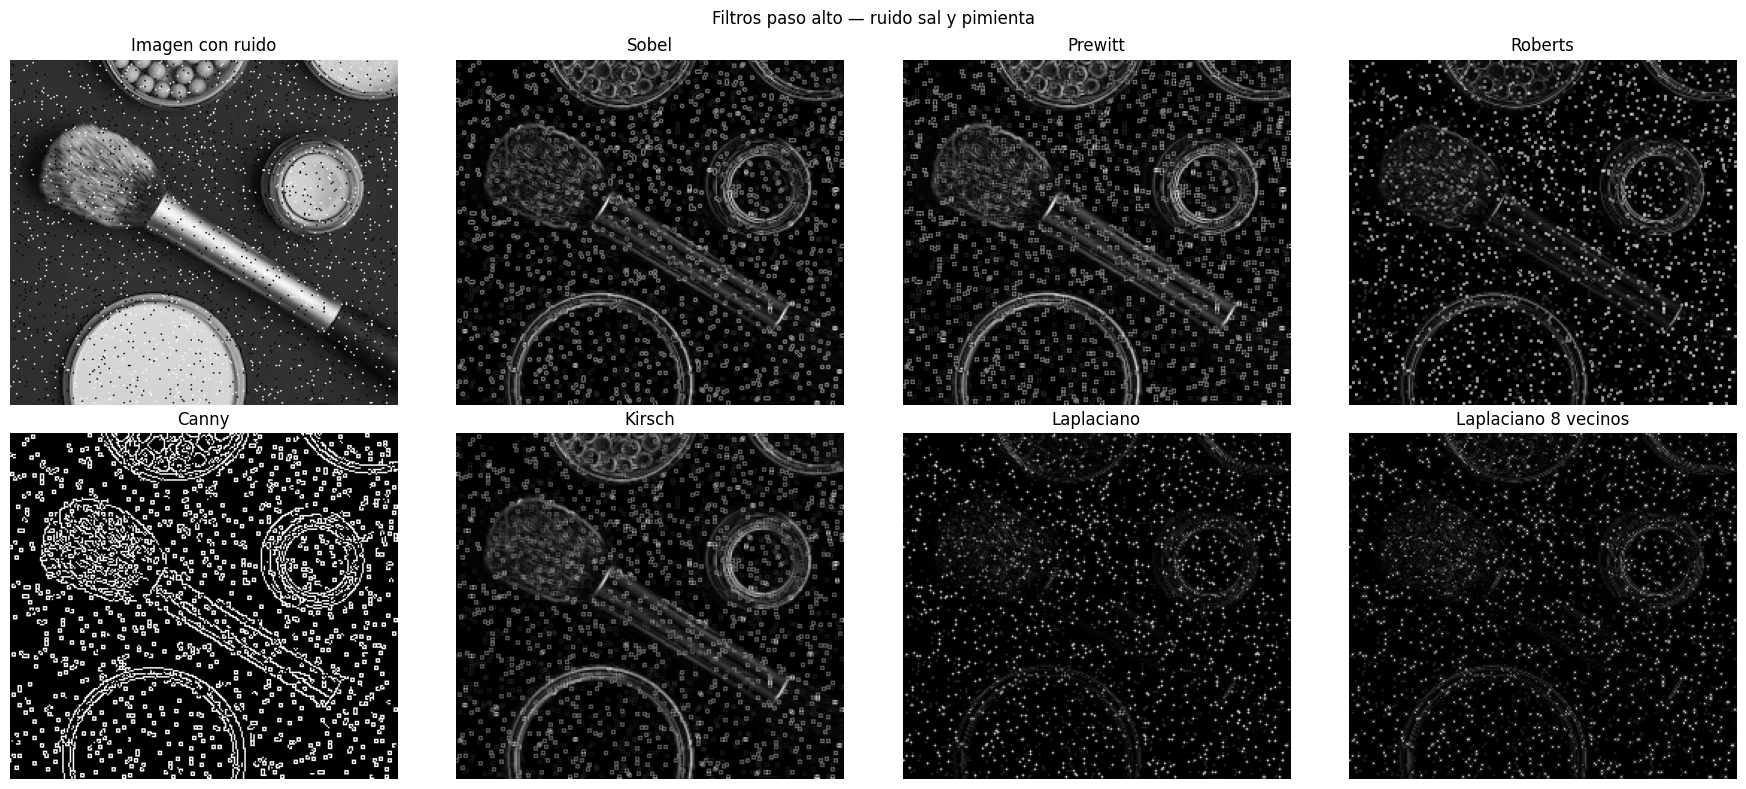

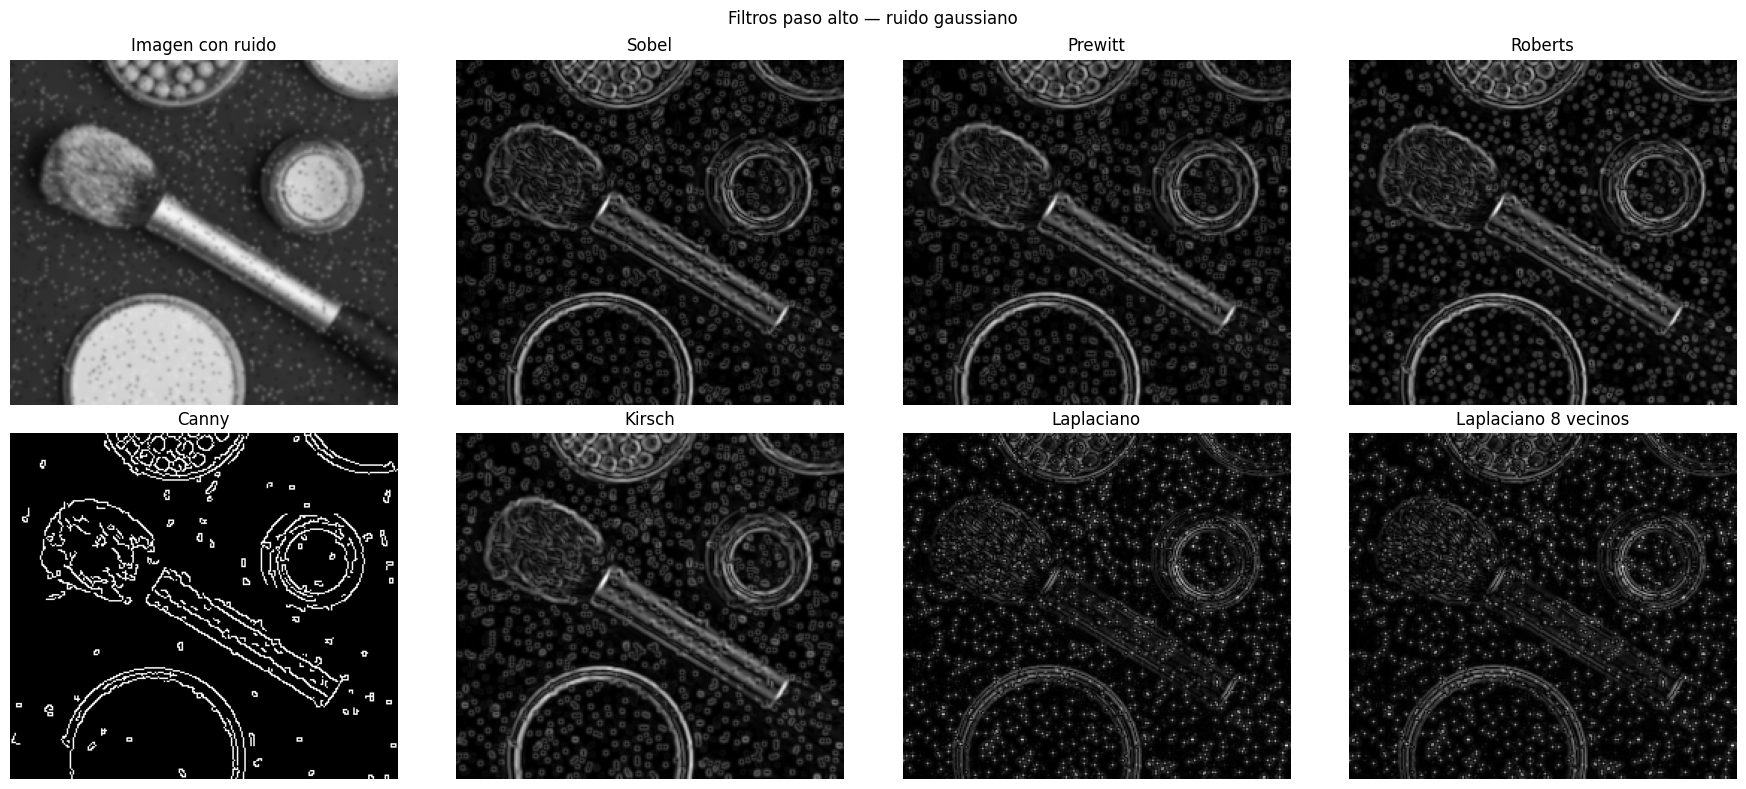

In [11]:
def normalizar_bordes(resultado):
    resultado = np.abs(resultado).astype(np.float32)
    return cv2.normalize(
        resultado, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)


def aplicar_filtros_paso_alto(img):
    img = img.astype(np.uint8)
    img_float = img.astype(np.float32)

    # Sobel
    sobel_x = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    sobel = normalizar_bordes(cv2.magnitude(sobel_x, sobel_y))

    # Prewitt
    prewitt_x = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float32)
    prewitt_y = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)
    px = cv2.filter2D(img_float, cv2.CV_32F, prewitt_x)
    py = cv2.filter2D(img_float, cv2.CV_32F, prewitt_y)
    prewitt = normalizar_bordes(cv2.magnitude(px, py))

    # Roberts
    roberts_x = np.array([[1, 0], [0, -1]], dtype=np.float32)
    roberts_y = np.array([[0, 1], [-1, 0]], dtype=np.float32)
    rx = cv2.filter2D(img_float, cv2.CV_32F, roberts_x)
    ry = cv2.filter2D(img_float, cv2.CV_32F, roberts_y)
    roberts = normalizar_bordes(cv2.magnitude(rx, ry))

    # Canny
    canny = cv2.Canny(img, 100, 200)

    # Kirsch: ocho direcciones
    kirsch_kernels = [
        [[5, 5, 5], [-3, 0, -3], [-3, -3, -3]],
        [[5, 5, -3], [5, 0, -3], [-3, -3, -3]],
        [[5, -3, -3], [5, 0, -3], [5, -3, -3]],
        [[-3, -3, -3], [5, 0, -3], [5, 5, -3]],
        [[-3, -3, -3], [-3, 0, -3], [5, 5, 5]],
        [[-3, -3, -3], [-3, 0, 5], [-3, 5, 5]],
        [[-3, -3, 5], [-3, 0, 5], [-3, -3, 5]],
        [[-3, 5, 5], [-3, 0, 5], [-3, -3, -3]],
    ]
    respuestas = [
        np.abs(cv2.filter2D(img_float, cv2.CV_32F, np.array(k, dtype=np.float32)))
        for k in kirsch_kernels
    ]
    kirsch = normalizar_bordes(np.maximum.reduce(respuestas))

    # Laplaciano de 4 vecinos
    laplaciano = normalizar_bordes(cv2.Laplacian(img, cv2.CV_32F))

    # Laplaciano de 8 vecinos
    kernel_laplaciano_8 = np.array(
        [[1, 1, 1], [1, -8, 1], [1, 1, 1]], dtype=np.float32
    )
    laplaciano_8 = normalizar_bordes(
        cv2.filter2D(img_float, cv2.CV_32F, kernel_laplaciano_8)
    )

    return [
        ("Sobel", sobel),
        ("Prewitt", prewitt),
        ("Roberts", roberts),
        ("Canny", canny),
        ("Kirsch", kirsch),
        ("Laplaciano", laplaciano),
        ("Laplaciano 8 vecinos", laplaciano_8),
    ]


def mostrar_matriz_paso_alto(img_con_ruido, nombre):
    resultados = [
        ("Imagen con ruido", img_con_ruido),
        *aplicar_filtros_paso_alto(img_con_ruido),
    ]

    fig, axs = plt.subplots(2, 4, figsize=(18, 8))
    axs = axs.ravel()

    for ax, (titulo, resultado) in zip(axs, resultados):
        ax.imshow(resultado, cmap="gray", vmin=0, vmax=255)
        ax.set_title(titulo)
        ax.axis("off")

    # Ocultar la décima celda, que queda vacía
    for ax in axs[len(resultados):]:
        ax.axis("off")

    fig.suptitle(f"Filtros paso alto — ruido {nombre}")
    plt.tight_layout()
    plt.show()


mostrar_matriz_paso_alto(imagen_sal_pimienta, "sal y pimienta")
mostrar_matriz_paso_alto(imagen_gaussiana, "gaussiano")

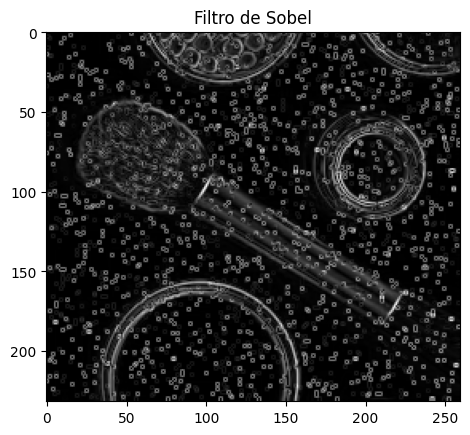

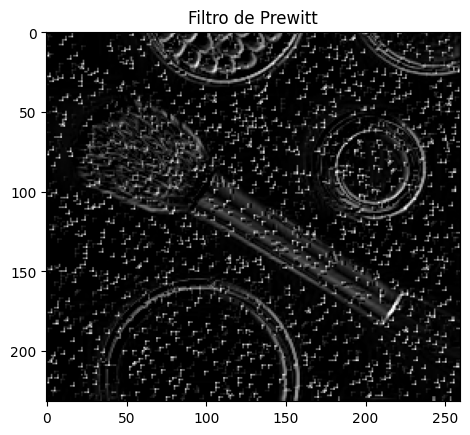

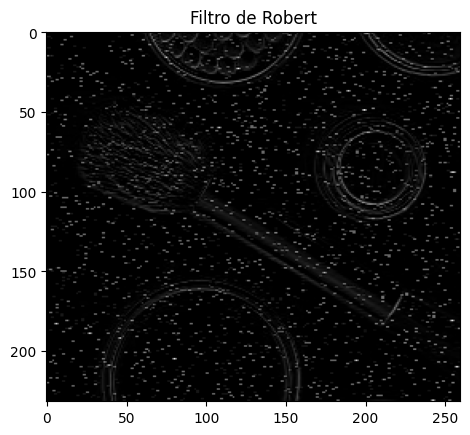

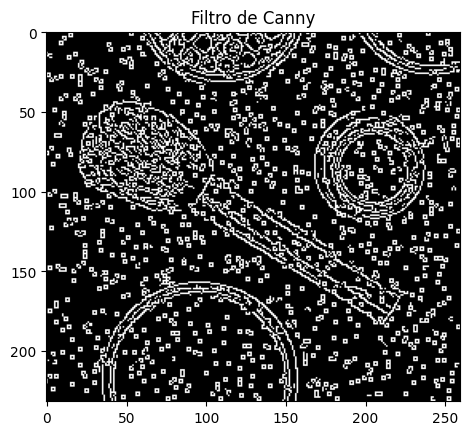

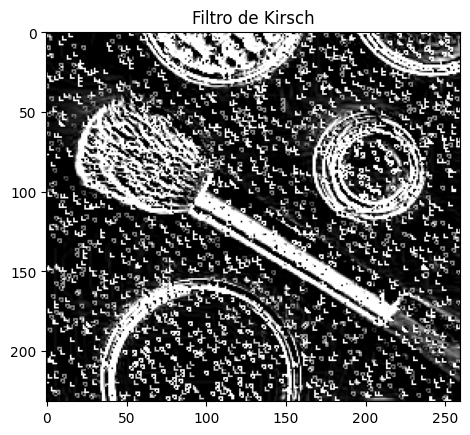

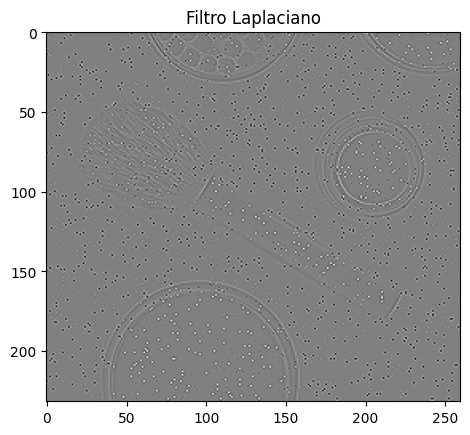

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\filter.dispatch.cpp:1603: error: (-215:Assertion failed) !_src.empty() in function 'cv::filter2D'


In [9]:
# Aplicar el filtro de Sobel
sobel_x = cv2.Sobel(imagen_sal_pimienta, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(imagen_sal_pimienta, cv2.CV_64F, 0, 1, ksize=3)
bordes_sobel = cv2.magnitude(sobel_x, sobel_y)
plt.imshow(bordes_sobel, cmap='gray')
plt.title('Filtro de Sobel')
plt.show()

#PREWIT
# Definir el kernel de Prewitt
kernel_prewitt_x = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]],
dtype=np.float32)
kernel_prewitt_y = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]],
dtype=np.float32)
# Aplicar el filtro
bordes_prewitt_x = cv2.filter2D(imagen_sal_pimienta, -1, kernel_prewitt_x)
bordes_prewitt_y = cv2.filter2D(imagen_sal_pimienta, -1, kernel_prewitt_y)
bordes_prewitt = cv2.addWeighted(bordes_prewitt_x, 0.5, bordes_prewitt_y,
0.5, 0)
plt.imshow(bordes_prewitt, cmap='gray')
plt.title('Filtro de Prewitt')
plt.show()

#ROBERTS
import cv2 
import numpy as np 
import matplotlib.pyplot as plt 
# Cargar la imagen en escala de grises 
imagen = imagen_sal_pimienta
# Definir el kernel de Robert 
kernel_roberts_x = np.array([[1, 0], [0, -1]], dtype=np.float32) 
kernel_roberts_y = np.array([[0, 1], [-1, 0]], dtype=np.float32) 
# Aplicar el filtro 
bordes_roberts_x = cv2.filter2D(imagen, -1, kernel_roberts_x) 
bordes_roberts_y = cv2.filter2D(imagen, -1, kernel_roberts_y) 
bordes_roberts = cv2.addWeighted(bordes_roberts_x, 0.5, bordes_roberts_y, 
0.5, 0) 
plt.imshow(bordes_roberts, cmap='gray') 
plt.title('Filtro de Robert') 
plt.show() 

#CANNY
# Aplicar el filtro de Canny 
bordes_canny = cv2.Canny(imagen, 100, 200) 
plt.imshow(bordes_canny, cmap='gray') 
plt.title('Filtro de Canny') 
plt.show() 

#KIRSH
# Definir los ocho kernels de Kirsch 
kirsch_kernels = [ 
np.array([[5, 5, 5], [-3, 0, -3], [-3, -3, -3]]),  # Dirección norte 
np.array([[-3, 5, 5], [-3, 0, 5], [-3, -3, -3]]),  # Noreste 
np.array([[-3, -3, 5], [-3, 0, 5], [-3, -3, 5]]),  # Este 
#NOTA importante: Añadir los otros kernels para las demás direcciones... 
] 
# Aplicar cada kernel y tomar el máximo de las respuestas 
bordes_kirsch = np.max([cv2.filter2D(imagen, -1, kernel) for kernel in 
kirsch_kernels], axis=0) 
plt.imshow(bordes_kirsch, cmap='gray') 
plt.title('Filtro de Kirsch') 
plt.show() 

#LAPLACIANO
# Aplicar el filtro Laplaciano 
laplaciano = cv2.Laplacian(imagen, cv2.CV_64F) 
plt.imshow(laplaciano, cmap='gray') 
plt.title('Filtro Laplaciano') 
plt.show() 

#LAPLACIANO DE 8 VECINOS
import cv2 
import numpy as np 
import matplotlib.pyplot as plt 
# Cargar la imagen en escala de grises 
image = cv2.imread('ruta_a_tu_imagen.jpg', cv2.IMREAD_GRAYSCALE) 
# Definir la máscara Laplaciana de 8 vecinos 
laplacian_kernel_8_neighbors = np.array([ 
[1,  1, 1], 
[1, -8, 1], 
[1,  1, 1] 
]) 
# Aplicar el filtro Laplaciano usando la máscara de 8 vecinos 
laplacian_8_neighbors = cv2.filter2D(image, -1, 
laplacian_kernel_8_neighbors) 
# Visualizar el resultado 
plt.figure(figsize=(10,5)) 
plt.subplot(1, 2, 1) 
plt.title("Imagen Original") 
plt.imshow(image, cmap='gray') 
plt.axis('off') 
plt.subplot(1, 2, 2) 
plt.title("Laplaciano de 8 Vecinos") 
plt.imshow(laplacian_8_neighbors, cmap='gray') 
plt.axis('off') 
plt.show() 

